In [1]:
import sys
print(sys.executable)

c:\Users\imsra\AppData\Local\Programs\Python\Python312\python.exe


In [2]:
%pip install pandas huggingface_hub

  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
   ---------------------------------------- 0.0/855.2 kB ? eta -:--:--
   ---------------------------------------- 855.2/855.2 kB 6.3 MB/s  0:00:00
   ---------------------------------------- 0.0/3.8 MB ? eta -:--:--
   ---------- ----------------------------- 1.0/3.8 MB 7.2 MB/s eta 0:00:01
   ------------------------ --------------- 2.4/3.8 MB 5.6 MB/s eta 0:00:01
   ---------------------------------------- 3.8/3.8 MB 6.3 MB/s  0:00:00
Using cached idna-3.20-py3-none-any.whl (69 kB)

  Attempting uninstall: idna

    Found existing installation: idna 3.11

    Uninstalling idna-3.11:

      Successfully uninstalled idna-3.11

   ----- ---------------------------------- 1/8 [idna]
   ----- ---------------------------------- 1/8 [idna]
   --------------- ------------------------ 3/8 [fsspec]
   --------------- ------------------------ 3/8 [fsspec]
   --------------- ------------------------ 3/8 [fsspec]
   --------------- ----


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
from huggingface_hub import hf_hub_download

print("Pandas version:", pd.__version__)
print("Libraries imported successfully!")

Pandas version: 2.3.3
Libraries imported successfully!


c:\Users\imsra\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
from huggingface_hub import hf_hub_download
import pandas as pd

repo_id = "onullusoy/harmful-contents"

train_csv = hf_hub_download(
    repo_id=repo_id,
    filename="csv/train.csv",
    repo_type="dataset"
)

print("Training CSV downloaded successfully!")
print(train_csv)

Training CSV downloaded successfully!
C:\Users\imsra\.cache\huggingface\hub\datasets--onullusoy--harmful-contents\snapshots\dbad8562be775688cd9949c825f3ac3238e5688c\csv\train.csv


c:\Users\imsra\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\imsra\.cache\huggingface\hub\datasets--onullusoy--harmful-contents. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


In [5]:
train_df = pd.read_csv(train_csv)

print("Dataset shape:", train_df.shape)

display(train_df.head())

Dataset shape: (3609, 17)


,name,alcohol,drugs,weapons,gambling,nudity,sexy,smoking,violence,mask_alcohol,mask_drugs,mask_weapons,mask_gambling,mask_nudity,mask_sexy,mask_smoking,mask_violence
0,1.jpg,0,0,1,0,0,0,0,1,0,0,1,0,0,0,0,1
1,2.jpg,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1
2,6.jpg,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
3,7.jpg,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
4,8.jpg,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0


In [6]:
print("Number of images:", len(train_df))

print("\nColumn names:")
print(train_df.columns.tolist())

category_cols = [
    "alcohol", "drugs", "weapons", "gambling",
    "nudity", "sexy", "smoking", "violence"
]

print("\nCategory label counts:")
display(train_df[category_cols].sum().sort_values(ascending=False))

print("\nMissing values:")
print(train_df[category_cols].isnull().sum())

Number of images: 3609

Column names:
['name', 'alcohol', 'drugs', 'weapons', 'gambling', 'nudity', 'sexy', 'smoking', 'violence', 'mask_alcohol', 'mask_drugs', 'mask_weapons', 'mask_gambling', 'mask_nudity', 'mask_sexy', 'mask_smoking', 'mask_violence']

Category label counts:


violence    481
sexy        461
weapons     417
nudity      361
smoking     357
gambling    217
alcohol     213
drugs       177
dtype: int64


Missing values:
alcohol     0
drugs       0
weapons     0
gambling    0
nudity      0
sexy        0
smoking     0
violence    0
dtype: int64


In [7]:
category_cols = [
    "alcohol", "drugs", "weapons", "gambling",
    "nudity", "sexy", "smoking", "violence"
]

train_df["potentially_unsafe"] = (
    train_df[category_cols].max(axis=1)
).astype(int)

print("Binary label distribution:")
print(train_df["potentially_unsafe"].value_counts())

print("\nLabel percentages:")
print(
    (train_df["potentially_unsafe"].value_counts(normalize=True) * 100)
    .round(2)
)

Binary label distribution:
potentially_unsafe
1    1900
0    1709
Name: count, dtype: int64

Label percentages:
potentially_unsafe
1    52.65
0    47.35
Name: proportion, dtype: float64


In [8]:
from huggingface_hub import HfApi

repo_id = "onullusoy/harmful-contents"

api = HfApi()
files = api.list_repo_files(
    repo_id=repo_id,
    repo_type="dataset"
)

print("Number of files:", len(files))

for file in files[:40]:
    print(file)

Number of files: 5158
.gitattributes
README.md
csv/test.csv
csv/train.csv
csv/val.csv
data/test/10.jpg
data/test/1013.jpg
data/test/1016.jpg
data/test/1017.jpg
data/test/1022.jpg
data/test/1029.jpg
data/test/1031.jpg
data/test/1040.jpg
data/test/1041.jpg
data/test/1044.jpg
data/test/1046.jpg
data/test/1063.jpg
data/test/1066.jpeg
data/test/1067.jpg
data/test/1070.jpeg
data/test/1084.jpg
data/test/1088.jpg
data/test/1110.png
data/test/1119.jpg
data/test/1122.jpg
data/test/1132.jpg
data/test/1138.png
data/test/1140.jpg
data/test/1146.jpg
data/test/1149.jpg
data/test/1155.jpg
data/test/1156.jpg
data/test/1157.jpg
data/test/1161.jpg
data/test/1170.jpg
data/test/1185.jpg
data/test/1194.jpg
data/test/1206.jpg
data/test/1218.jpg
data/test/1220.jpg


In [9]:
from huggingface_hub import hf_hub_download
import pandas as pd

repo_id = "onullusoy/harmful-contents"

# Download the three small CSV files
train_path = hf_hub_download(
    repo_id=repo_id,
    filename="csv/train.csv",
    repo_type="dataset"
)

val_path = hf_hub_download(
    repo_id=repo_id,
    filename="csv/val.csv",
    repo_type="dataset"
)

test_path = hf_hub_download(
    repo_id=repo_id,
    filename="csv/test.csv",
    repo_type="dataset"
)

# Load the CSV files
train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)
test_df = pd.read_csv(test_path)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nTraining columns:")
print(train_df.columns.tolist())

Training images: 3609
Validation images: 771
Testing images: 773

Training columns:
['name', 'alcohol', 'drugs', 'weapons', 'gambling', 'nudity', 'sexy', 'smoking', 'violence', 'mask_alcohol', 'mask_drugs', 'mask_weapons', 'mask_gambling', 'mask_nudity', 'mask_sexy', 'mask_smoking', 'mask_violence']


In [10]:
category_cols = [
    "alcohol", "drugs", "weapons", "gambling",
    "nudity", "sexy", "smoking", "violence"
]

for df in [train_df, val_df, test_df]:
    df["potentially_unsafe"] = (
        df[category_cols].max(axis=1)
    ).astype(int)

print("Training labels:")
print(train_df["potentially_unsafe"].value_counts())

print("\nValidation labels:")
print(val_df["potentially_unsafe"].value_counts())

print("\nTesting labels:")
print(test_df["potentially_unsafe"].value_counts())

Training labels:
potentially_unsafe
1    1900
0    1709
Name: count, dtype: int64

Validation labels:
potentially_unsafe
1    402
0    369
Name: count, dtype: int64

Testing labels:
potentially_unsafe
1    409
0    364
Name: count, dtype: int64


In [11]:
files = api.list_repo_files(
    repo_id=repo_id,
    repo_type="dataset"
)

for folder in ["data/train/", "data/val/", "data/test/"]:
    matching = [f for f in files if f.startswith(folder)]

    print(f"\n{folder}")
    print("Number of files:", len(matching))
    print("Examples:", matching[:5])


data/train/
Number of files: 3609
Examples: ['data/train/1.jpg', 'data/train/100.jpg', 'data/train/1000.jpg', 'data/train/1002.jpg', 'data/train/1003.jpg']

data/val/
Number of files: 771
Examples: ['data/val/1001.jpg', 'data/val/1007.jpg', 'data/val/1008.jpg', 'data/val/1015.jpg', 'data/val/1020.jpg']

data/test/
Number of files: 773
Examples: ['data/test/10.jpg', 'data/test/1013.jpg', 'data/test/1016.jpg', 'data/test/1017.jpg', 'data/test/1022.jpg']


c:\Users\imsra\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\imsra\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


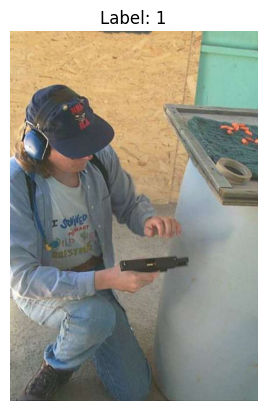

Image name: 1.jpg
Image size: (685, 1024)
Image mode: RGB


In [12]:
from huggingface_hub import hf_hub_download
from PIL import Image
import matplotlib.pyplot as plt

# Select the first training image
sample_name = train_df.iloc[0]["name"]

# Download only this image
sample_path = hf_hub_download(
    repo_id=repo_id,
    filename=f"data/train/{sample_name}",
    repo_type="dataset"
)

# Open and display the image
img = Image.open(sample_path)

plt.imshow(img)
plt.axis("off")
plt.title(
    f"Label: {train_df.iloc[0]['potentially_unsafe']}"
)
plt.show()

print("Image name:", sample_name)
print("Image size:", img.size)
print("Image mode:", img.mode)

In [13]:
sample_row = train_df[train_df["name"] == sample_name]

display(sample_row[[
    "name",
    "alcohol",
    "drugs",
    "weapons",
    "gambling",
    "nudity",
    "sexy",
    "smoking",
    "violence",
    "potentially_unsafe"
]])

,name,alcohol,drugs,weapons,gambling,nudity,sexy,smoking,violence,potentially_unsafe
0,1.jpg,0,0,1,0,0,0,0,1,1


In [14]:
%pip install tensorflow pillow matplotlib scikit-learn

  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
   ---------------------------------------- 0.0/350.9 MB ? eta -:--:--
   ---------------------------------------- 1.0/350.9 MB 8.5 MB/s eta 0:00:42
    --------------------------------------- 5.8/350.9 MB 17.6 MB/s eta 0:00:20
   - -------------------------------------- 12.1/350.9 MB 22.2 MB/s eta 0:00:16
   - -------------------------------------- 16.8/350.9 MB 24.0 MB/s eta 0:00:14
   -- ------------------------------------- 21.5/350.9 MB 23.0 MB/s eta 0:00:15
   --- ------------------------------------ 27.3/350.9 MB 23.4 MB/s eta 0:00:14
   --- ------------------------------------ 31.5/350.9 MB 23.0 MB/s eta 0:00:14
   ---- ----------------------------------- 37.0/350.9 MB 23.3 MB/s eta 0:00:14
   ---- ----------------------------------- 43.0/350.9 MB 23.8 MB/s eta 0:00:13
   ----- ---------------------------------- 48.0/350.9 MB 24.0 MB/s eta 0:00:13
   ------ --------------------------------- 54.8/350.9 


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [15]:
import tensorflow as tf
import sklearn
from PIL import Image

print("TensorFlow version:", tf.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Scikit-learn version: 1.9.1
Libraries imported successfully!


In [16]:
import numpy as np
from PIL import Image

IMG_SIZE = (128, 128)

def load_image(image_path):
    img = Image.open(image_path).convert("RGB")   ## the image has three colors
    img = img.resize(IMG_SIZE)                     ## makes every image the same size
    img_array = np.array(img, dtype=np.float32) / 255.0  ## onverts the image into num so that CNN can process
    return img_array

In [17]:
processed_img = load_image(sample_path)

print("Processed image shape:", processed_img.shape)
print("Minimum pixel value:", processed_img.min())
print("Maximum pixel value:", processed_img.max())

Processed image shape: (128, 128, 3)
Minimum pixel value: 0.1254902
Maximum pixel value: 1.0


### Inspecting Training Dataset

In [19]:
print("Column names:")
print(train_df.columns.tolist())

print("\nFirst 5 image records:")
print(train_df.head())

print("\nLabel counts:")
print(train_df["potentially_unsafe"].value_counts())

Column names:
['name', 'alcohol', 'drugs', 'weapons', 'gambling', 'nudity', 'sexy', 'smoking', 'violence', 'mask_alcohol', 'mask_drugs', 'mask_weapons', 'mask_gambling', 'mask_nudity', 'mask_sexy', 'mask_smoking', 'mask_violence', 'potentially_unsafe']

First 5 image records:
    name  alcohol  drugs  weapons  gambling  nudity  sexy  smoking  violence  \
0  1.jpg        0      0        1         0       0     0        0         1   
1  2.jpg        0      0        0         0       0     0        0         0   
2  6.jpg        0      0        0         0       0     0        0         0   
3  7.jpg        0      0        0         0       0     0        0         0   
4  8.jpg        0      0        0         0       0     0        0         0   

   mask_alcohol  mask_drugs  mask_weapons  mask_gambling  mask_nudity  \
0             0           0             1              0            0   
1             0           0             1              0            0   
2             0        